# Tutorial: Transformer encoder for sequences

In `tf.keras_rnn.ipynb` an LSTM learned to predict the next letter of eight short 'songs'. In this tutorial a small **Transformer encoder** learns the same task, with the same data and the same robustness test, so the two models can be compared side by side.

Instead of reading a song one letter at a time, the Transformer lets every letter attend to every other letter at once (see `attention_numpy.ipynb`). Keras provides the attention part as `layers.MultiHeadAttention` - see https://www.tensorflow.org/api_docs/python/tf/keras/layers/MultiHeadAttention. We combine it with the other parts of a Transformer block ourselves.

# Background - The Transformer encoder block

An encoder block has two parts. Each part is followed by a **residual connection** (its input is added back onto its output, so information can skip past it) and **layer normalization** (which keeps the numbers in a stable range):

1. **Multi-head self-attention**: every position gathers information from every other position.
2. **Feed-forward network**: two Dense layers, applied to each position separately.

Attention ignores order, so before the block each letter's embedding is added to a **position embedding**. The whole model looks like this:

```
9 letters -> letter embedding + position embedding
          -> [ self-attention -> add & normalize -> feed-forward -> add & normalize ]
          -> average over the 9 positions -> softmax over 26 letters
```

Blocks can be stacked, but one block is plenty for eight songs.

# Step 0 - Setup the learning environment

As in the LSTM tutorial, the batch size is small (4) because there are only eight songs, and we train for a larger number of epochs.

In [1]:
'''
tf.keras_transformer_songs.py

Trains a small Transformer encoder to predict the next letter in a 'song'.
Uses the same data and robustness test as tf.keras_rnn.ipynb, so the two
models can be compared. Trains in a few seconds on a CPU.
'''

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow's information messages
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

tf.get_logger().setLevel('ERROR')          # hide TensorFlow's deprecation warnings
np.random.seed(2)          # for consistency
tf.random.set_seed(2)

batch_size = 4
epochs = 100

print(tf.__version__)
print('Environment is ready!')


2.15.0
Environment is ready!


# Step 1 - Define and prepare the data

These are the same eight songs as in the LSTM tutorial: each letter stands for a part of a song, the first nine letters are the input, and the final letter is the label to predict.

There is one difference in how the letters reach the network. The LSTM was given each letter as a single number, its position in the alphabet. Here each letter stays an integer index, and the model's first layer, an `Embedding`, learns a whole vector of numbers for each letter. This is how Transformers, and language models in general, read their input.

In [2]:
alphabet = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
song = [
    ['X', 'X', 'A', 'H', 'F', 'E', 'C', 'E', 'B', 'M'],
    ['Y', 'Y', 'Y', 'A', 'H', 'F', 'E', 'C', 'E', 'N'],
    ['F', 'E', 'F', 'C', 'D', 'E', 'F', 'D', 'B', 'O'],
    ['F', 'F', 'F', 'G', 'H', 'G', 'G', 'F', 'E', 'P'],
    ['C', 'B', 'A', 'H', 'F', 'E', 'C', 'E', 'B', 'Q'],
    ['Z', 'X', 'B', 'A', 'B', 'C', 'D', 'E', 'F', 'R'],
    ['W', 'F', 'G', 'H', 'H', 'H', 'G', 'F', 'E', 'L'],
    ['W', 'X', 'Y', 'Z', 'D', 'E', 'F', 'G', 'H', 'K']]


def encode_songs(song_list):
    """Turn songs of letters into alphabet indices. The last letter of each song is the label."""
    data = np.array([[alphabet.find(el) for el in row] for row in song_list])
    sequences = data[:, :-1]                                              # the first 9 letters
    labels = tf.keras.utils.to_categorical(data[:, -1], len(alphabet))   # one-hot encoded last letter
    return sequences, labels


songs, labels = encode_songs(song)

print(songs)
print('songs shape (samples, time steps):', songs.shape)
print('labels shape (samples, letters):  ', labels.shape)

[[23 23  0  7  5  4  2  4  1]
 [24 24 24  0  7  5  4  2  4]
 [ 5  4  5  2  3  4  5  3  1]
 [ 5  5  5  6  7  6  6  5  4]
 [ 2  1  0  7  5  4  2  4  1]
 [25 23  1  0  1  2  3  4  5]
 [22  5  6  7  7  7  6  5  4]
 [22 23 24 25  3  4  5  6  7]]
songs shape (samples, time steps): (8, 9)
labels shape (samples, letters):   (8, 26)


# Step 2 - Define model architecture

We define two layers of our own, written as Python classes that extend `layers.Layer`:

* `PositionalEmbedding` adds a learned vector for each letter and a learned vector for each position.
* `TransformerBlock` is the encoder block from the Background section. `MultiHeadAttention(x, x)` means the queries, keys and values all come from the same sequence, which is what *self*-attention means.

Then we stack them in a `Sequential` model, as in the earlier tutorials. `GlobalAveragePooling1D` averages the 9 position vectors into one vector per song, and the final `Dense` layer gives a probability for each of the 26 letters.

In [3]:
class PositionalEmbedding(layers.Layer):
    """Turns letter indices into vectors: a learned vector per letter plus a learned vector per position."""

    def __init__(self, seq_len, vocab_size, d_model, **kwargs):
        super().__init__(**kwargs)
        self.token_embedding = layers.Embedding(vocab_size, d_model)
        self.position_embedding = layers.Embedding(seq_len, d_model)

    def call(self, x):
        positions = tf.range(tf.shape(x)[-1])        # 0, 1, ..., seq_len - 1
        return self.token_embedding(x) + self.position_embedding(positions)


class TransformerBlock(layers.Layer):
    """Self-attention and a feed-forward network, each with a residual connection and layer normalization."""

    def __init__(self, d_model, num_heads, d_ff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.feed_forward = tf.keras.Sequential([
            layers.Dense(d_ff, activation='relu'),
            layers.Dense(d_model),
        ])
        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, training=False, return_attention=False):
        # 1. self-attention: the queries, keys and values all come from x
        attn_out, attn_scores = self.attention(x, x, return_attention_scores=True, training=training)
        x = self.norm1(x + self.dropout1(attn_out, training=training))      # add & normalize
        # 2. feed-forward network, applied to each position separately
        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout2(ff_out, training=training))        # add & normalize
        if return_attention:
            return x, attn_scores
        return x


seq_len = songs.shape[1]       # 9 letters per song
vocab_size = len(alphabet)     # 26 possible letters
d_model = 32                   # length of each letter's vector
num_heads = 4                  # attention heads
d_ff = 64                      # width of the feed-forward network

model = tf.keras.Sequential()
model.add(tf.keras.Input(shape=(seq_len,), dtype='int32'))
model.add(PositionalEmbedding(seq_len, vocab_size, d_model))
model.add(TransformerBlock(d_model, num_heads, d_ff))
model.add(layers.GlobalAveragePooling1D())
model.add(layers.Dense(vocab_size, activation='softmax'))

# Print a quick summary of the model to verify our work
model.summary()

# Transformers are usually trained with the Adam optimizer
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 positional_embedding (Posi  (None, 9, 32)             1120      
 tionalEmbedding)                                                
                                                                 
 transformer_block (Transfo  (None, 9, 32)             8544      
 rmerBlock)                                                      
                                                                 
 global_average_pooling1d (  (None, 32)                0         
 GlobalAveragePooling1D)                                         
                                                                 
 dense_2 (Dense)             (None, 26)                858       
                                                                 
Total params: 10522 (41.10 KB)
Trainable params: 10522 (41.10 KB)
Non-trainable params: 0 (0.00 Byte)
____________________

# Step 3 - Train the model

We train quietly (`verbose=0`) and plot the loss and accuracy for each epoch afterwards.

Training accuracy: 100%


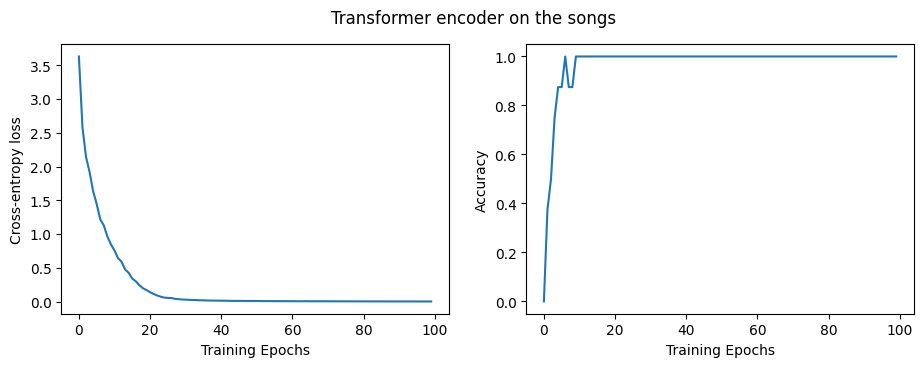

In [4]:
history = model.fit(songs, labels, batch_size=batch_size, epochs=epochs, shuffle=True, verbose=0)
scores = model.evaluate(songs, labels, verbose=0)

print('Training accuracy: {0:.0%}'.format(scores[1]))

# Plot the training loss and accuracy by epoch
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history.history['loss'])
axes[0].set_xlabel('Training Epochs')
axes[0].set_ylabel('Cross-entropy loss')
axes[1].plot(history.history['accuracy'])
axes[1].set_xlabel('Training Epochs')
axes[1].set_ylabel('Accuracy')
plt.suptitle('Transformer encoder on the songs')
plt.show()

# Step 4 - Print some sample results

In [5]:
def print_predictions(sequences, targets):
    """Predict the next letter of every song and compare it with the real one."""
    predictions = model.predict(sequences, verbose=0)
    num_correct = 0
    for i in range(len(sequences)):
        letters_in = [alphabet[k] for k in sequences[i]]
        predicted = np.argmax(predictions[i])
        if predicted == np.argmax(targets[i]):
            msg = 'Correct!'
            num_correct += 1
        else:
            msg = 'Incorrect'
        print("{0} -> {1} ... {2}".format(letters_in, alphabet[predicted], msg))
    print('{0} of {1} correct'.format(num_correct, len(sequences)))


print_predictions(songs, labels)

['X', 'X', 'A', 'H', 'F', 'E', 'C', 'E', 'B'] -> M ... Correct!
['Y', 'Y', 'Y', 'A', 'H', 'F', 'E', 'C', 'E'] -> N ... Correct!
['F', 'E', 'F', 'C', 'D', 'E', 'F', 'D', 'B'] -> O ... Correct!
['F', 'F', 'F', 'G', 'H', 'G', 'G', 'F', 'E'] -> P ... Correct!
['C', 'B', 'A', 'H', 'F', 'E', 'C', 'E', 'B'] -> Q ... Correct!
['Z', 'X', 'B', 'A', 'B', 'C', 'D', 'E', 'F'] -> R ... Correct!
['W', 'F', 'G', 'H', 'H', 'H', 'G', 'F', 'E'] -> L ... Correct!
['W', 'X', 'Y', 'Z', 'D', 'E', 'F', 'G', 'H'] -> K ... Correct!
8 of 8 correct


# Step 5 - Testing for robustness / generalization

These are the same slightly changed songs as in Step 5 of `tf.keras_rnn.ipynb`. A letter or two has been changed in each song, but the answer should stay the same. How does the Transformer do? Run Step 5 of the LSTM tutorial and compare.

In [6]:
testsong = [
    ['X', 'X', 'A', 'H', 'G', 'E', 'C', 'E', 'B', 'M'],
    ['Y', 'Y', 'Y', 'B', 'H', 'F', 'F', 'C', 'E', 'N'],
    ['F', 'E', 'F', 'C', 'D', 'E', 'F', 'D', 'B', 'O'],
    ['F', 'F', 'F', 'G', 'G', 'G', 'G', 'F', 'O', 'P'],
    ['C', 'B', 'A', 'H', 'F', 'E', 'D', 'E', 'B', 'Q'],
    ['Z', 'X', 'B', 'A', 'B', 'E', 'E', 'E', 'F', 'R'],
    ['W', 'F', 'G', 'H', 'H', 'H', 'H', 'F', 'E', 'L'],
    ['W', 'X', 'Y', 'Z', 'D', 'E', 'F', 'G', 'G', 'K']]

# The encode_songs function from Step 1 does the conversion, so no code is repeated
testsongs, testlabels = encode_songs(testsong)
print_predictions(testsongs, testlabels)

['X', 'X', 'A', 'H', 'G', 'E', 'C', 'E', 'B'] -> M ... Correct!
['Y', 'Y', 'Y', 'B', 'H', 'F', 'F', 'C', 'E'] -> N ... Correct!
['F', 'E', 'F', 'C', 'D', 'E', 'F', 'D', 'B'] -> O ... Correct!
['F', 'F', 'F', 'G', 'G', 'G', 'G', 'F', 'O'] -> P ... Correct!
['C', 'B', 'A', 'H', 'F', 'E', 'D', 'E', 'B'] -> Q ... Correct!
['Z', 'X', 'B', 'A', 'B', 'E', 'E', 'E', 'F'] -> R ... Correct!
['W', 'F', 'G', 'H', 'H', 'H', 'H', 'F', 'E'] -> L ... Correct!
['W', 'X', 'Y', 'Z', 'D', 'E', 'F', 'G', 'G'] -> K ... Correct!
8 of 8 correct


# Step 6 - Look inside: the attention weights

`MultiHeadAttention` can also return its attention weights. Here we run one song through the embedding layer and the Transformer block and plot what each head attends to. Each row is a position in the song, and each column is a position it takes information from.

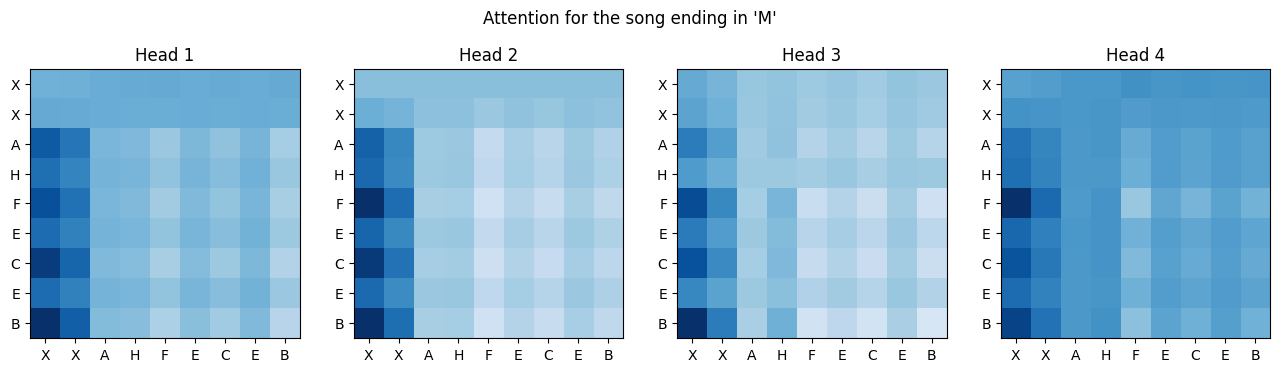

In [7]:
embedding_layer, transformer_block = model.layers[0], model.layers[1]

song_index = 0
x = embedding_layer(songs[song_index:song_index + 1])
_, attention_scores = transformer_block(x, return_attention=True)    # (1, num_heads, 9, 9)

letters = [alphabet[k] for k in songs[song_index]]
fig, axes = plt.subplots(1, num_heads, figsize=(16, 4))
for h in range(num_heads):
    axes[h].imshow(attention_scores[0, h], cmap='Blues', vmin=0)
    axes[h].set_xticks(range(seq_len))
    axes[h].set_xticklabels(letters)
    axes[h].set_yticks(range(seq_len))
    axes[h].set_yticklabels(letters)
    axes[h].set_title('Head {0}'.format(h + 1))
plt.suptitle("Attention for the song ending in '{0}'".format(alphabet[np.argmax(labels[song_index])]))
plt.show()

In our run, most of the heads look mainly at the first two letters of the song. Remember from the LSTM tutorial that the songs ending in M and Q differ only in their first two letters: those positions are the ones that tell the songs apart. Your plots may look a little different, because training starts from random weights.

**Things to try**

* Change `num_heads`, `d_model` or `d_ff` in Step 2.
* Add a second `TransformerBlock` before the pooling layer.
* Remove the position embedding by changing `PositionalEmbedding.call` to `return self.token_embedding(x)`. The model then only knows *which* letters a song contains, not their order. Can it still tell the songs apart?
* Change `song_index` in Step 6 to look at another song.